<a href="https://colab.research.google.com/github/mayatrissnawati-jpg/Proyek_Rice-Cammeo-Osmancik-_Kelompok3/blob/main/EDA_Kelompok_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Exploratory Data Analysis
## Dataset Rice Cammeo and Osmancik

### Deskripsi Dataset
Dataset ini berisi pengukuran karakteristik morfologi
butir beras dari dua varietas, yaitu Cammeo dan Osmancik.

### Unit Analisis
Satu baris merepresentasikan satu butir beras hasil
pengukuran citra.

### Tujuan Analisis
Mengeksplorasi karakteristik fisik beras dan memahami
hubungan antarfitur sebelum proses machine learning.

### Variabel Target
Class: Cammeo dan Osmancik.

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import zipfile
import io

from scipy.io import arff

sns.set_theme(style="whitegrid")

# Membaca dataset dari ZIP
zip_path = '/content/rice+cammeo+and+osmancik.zip'

with zipfile.ZipFile(zip_path, 'r') as z:

    print("Daftar file:")
    print(z.namelist())

    # Mencari file ARFF
    arff_file = [
        f for f in z.namelist()
        if f.lower().endswith('.arff')
    ][0]

    # Membaca ARFF sebagai teks
    with z.open(arff_file) as f:
        content = f.read().decode('utf-8')

    # Mengubah teks menjadi data
    data, meta = arff.loadarff(io.StringIO(content))

df = pd.DataFrame(data)

# Mengubah Class dari bytes menjadi string
df['Class'] = df['Class'].apply(
    lambda x: x.decode('utf-8') if isinstance(x, bytes) else x
)

print("\nDataset berhasil dimuat!")
print("Nama file:", arff_file)
print("Ukuran dataset:", df.shape)

display(df.head())

Daftar file:
['Citation_Request.txt', 'Rice_Cammeo_Osmancik.arff']

Dataset berhasil dimuat!
Nama file: Rice_Cammeo_Osmancik.arff
Ukuran dataset: (3810, 8)


,Area,Perimeter,Major_Axis_Length,Minor_Axis_Length,Eccentricity,Convex_Area,Extent,Class
0,15231.0,525.578979,229.749878,85.093788,0.928882,15617.0,0.572896,Cammeo
1,14656.0,494.311005,206.020065,91.730972,0.895405,15072.0,0.615436,Cammeo
2,14634.0,501.122009,214.106781,87.768288,0.912118,14954.0,0.693259,Cammeo
3,13176.0,458.342987,193.337387,87.448395,0.891861,13368.0,0.640669,Cammeo
4,14688.0,507.166992,211.743378,89.312454,0.906691,15262.0,0.646024,Cammeo


In [9]:
assert df.shape == (3810, 8), (
    f"Ukuran dataset tidak sesuai: {df.shape}"
)

print("PASS: Dataset memiliki 3810 baris dan 8 kolom.")

PASS: Dataset memiliki 3810 baris dan 8 kolom.


In [10]:
# Melihat 10 data pertama
display(df.head(10))

# Melihat informasi dataset
df.info()

# Melihat statistik numerik
display(df.describe())

# Melihat statistik kategori
display(df.describe(include='object'))

# Mengecek tipe data
print("\nTipe data:")
print(df.dtypes)

# Jumlah nilai unik
print("\nJumlah nilai unik:")
print(df.nunique())

,Area,Perimeter,Major_Axis_Length,Minor_Axis_Length,Eccentricity,Convex_Area,Extent,Class
0,15231.0,525.578979,229.749878,85.093788,0.928882,15617.0,0.572896,Cammeo
1,14656.0,494.311005,206.020065,91.730972,0.895405,15072.0,0.615436,Cammeo
2,14634.0,501.122009,214.106781,87.768288,0.912118,14954.0,0.693259,Cammeo
3,13176.0,458.342987,193.337387,87.448395,0.891861,13368.0,0.640669,Cammeo
4,14688.0,507.166992,211.743378,89.312454,0.906691,15262.0,0.646024,Cammeo
5,13479.0,477.015991,200.053055,86.650291,0.901328,13786.0,0.657897,Cammeo
6,15757.0,509.281006,207.296677,98.336136,0.880323,16150.0,0.589708,Cammeo
7,16405.0,526.570007,221.612518,95.436707,0.902521,16837.0,0.658888,Cammeo
8,14534.0,483.640991,196.650818,95.050682,0.875429,14932.0,0.649651,Cammeo
9,13485.0,471.570007,198.272644,87.727287,0.896789,13734.0,0.572320,Cammeo


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3810 entries, 0 to 3809
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Area               3810 non-null   float64
 1   Perimeter          3810 non-null   float64
 2   Major_Axis_Length  3810 non-null   float64
 3   Minor_Axis_Length  3810 non-null   float64
 4   Eccentricity       3810 non-null   float64
 5   Convex_Area        3810 non-null   float64
 6   Extent             3810 non-null   float64
 7   Class              3810 non-null   object 
dtypes: float64(7), object(1)
memory usage: 238.3+ KB


,Area,Perimeter,Major_Axis_Length,Minor_Axis_Length,Eccentricity,Convex_Area,Extent
count,3810.000000,3810.000000,3810.000000,3810.000000,3810.000000,3810.000000,3810.000000
mean,12667.727559,454.239180,188.776222,86.313750,0.886871,12952.496850,0.661934
std,1732.367706,35.597081,17.448679,5.729817,0.020818,1776.972042,0.077239
min,7551.000000,359.100006,145.264465,59.532406,0.777233,7723.000000,0.497413
25%,11370.500000,426.144753,174.353855,82.731695,0.872402,11626.250000,0.598862
50%,12421.500000,448.852493,185.810059,86.434647,0.889050,12706.500000,0.645361
75%,13950.000000,483.683746,203.550438,90.143677,0.902588,14284.000000,0.726562
max,18913.000000,548.445984,239.010498,107.542450,0.948007,19099.000000,0.861050


,Class
count,3810
unique,2
top,Osmancik
freq,2180



Tipe data:
Area                 float64
Perimeter            float64
Major_Axis_Length    float64
Minor_Axis_Length    float64
Eccentricity         float64
Convex_Area          float64
Extent               float64
Class                 object
dtype: object

Jumlah nilai unik:
Area                 2828
Perimeter            3738
Major_Axis_Length    3808
Minor_Axis_Length    3804
Eccentricity         3803
Convex_Area          2857
Extent               3804
Class                   2
dtype: int64


In [11]:
kamus_data = pd.DataFrame({
    'Nama Kolom': [
        'Area',
        'Perimeter',
        'Major_Axis_Length',
        'Minor_Axis_Length',
        'Eccentricity',
        'Convex_Area',
        'Extent',
        'Class'
    ],
    'Arti': [
        'Luas permukaan butir beras',
        'Keliling butir beras',
        'Panjang sumbu utama',
        'Panjang sumbu minor',
        'Tingkat kelonjongan bentuk',
        'Luas area cembung',
        'Rasio area terhadap bounding box',
        'Jenis varietas beras'
    ],
    'Peran': [
        'Fitur',
        'Fitur',
        'Fitur',
        'Fitur',
        'Fitur',
        'Fitur',
        'Fitur',
        'Target klasifikasi'
    ]
})

display(kamus_data)

,Nama Kolom,Arti,Peran
0,Area,Luas permukaan butir beras,Fitur
1,Perimeter,Keliling butir beras,Fitur
2,Major_Axis_Length,Panjang sumbu utama,Fitur
3,Minor_Axis_Length,Panjang sumbu minor,Fitur
4,Eccentricity,Tingkat kelonjongan bentuk,Fitur
5,Convex_Area,Luas area cembung,Fitur
6,Extent,Rasio area terhadap bounding box,Fitur
7,Class,Jenis varietas beras,Target klasifikasi


In [12]:
hilang = pd.DataFrame({
    'Jumlah': df.isna().sum(),
    'Persentase (%)': (
        df.isna().mean() * 100
    ).round(2)
})

display(hilang)

,Jumlah,Persentase (%)
Area,0,0.0
Perimeter,0,0.0
Major_Axis_Length,0,0.0
Minor_Axis_Length,0,0.0
Eccentricity,0,0.0
Convex_Area,0,0.0
Extent,0,0.0
Class,0,0.0


In [13]:
numerik = df.select_dtypes(include='number').columns

print("Pemeriksaan nilai nol:")

for kolom in numerik:
    print(kolom, ":", (df[kolom] == 0).sum())

print("\nPemeriksaan nilai negatif:")

for kolom in numerik:
    print(kolom, ":", (df[kolom] < 0).sum())

print("\nNilai unik Class:")
print(df['Class'].value_counts(dropna=False))

Pemeriksaan nilai nol:
Area : 0
Perimeter : 0
Major_Axis_Length : 0
Minor_Axis_Length : 0
Eccentricity : 0
Convex_Area : 0
Extent : 0

Pemeriksaan nilai negatif:
Area : 0
Perimeter : 0
Major_Axis_Length : 0
Minor_Axis_Length : 0
Eccentricity : 0
Convex_Area : 0
Extent : 0

Nilai unik Class:
Class
Osmancik    2180
Cammeo      1630
Name: count, dtype: int64


In [14]:
print(
    "Jumlah baris identik:",
    df.duplicated().sum()
)

Jumlah baris identik: 0


In [15]:
jumlah_unik = df.nunique()

kolom_konstan = jumlah_unik[
    jumlah_unik <= 1
]

kolom_identifier = jumlah_unik[
    jumlah_unik > 0.9 * len(df)
]

print("Kolom konstan:")
print(list(kolom_konstan.index))

print("\nKolom hampir unik:")
print(list(kolom_identifier.index))

Kolom konstan:
[]

Kolom hampir unik:
['Perimeter', 'Major_Axis_Length', 'Minor_Axis_Length', 'Eccentricity', 'Extent']


In [16]:
print("Pemeriksaan nilai mustahil:")

for kolom in numerik:
    print(
        kolom,
        "nilai tidak positif:",
        (df[kolom] <= 0).sum()
    )

Pemeriksaan nilai mustahil:
Area nilai tidak positif: 0
Perimeter nilai tidak positif: 0
Major_Axis_Length nilai tidak positif: 0
Minor_Axis_Length nilai tidak positif: 0
Eccentricity nilai tidak positif: 0
Convex_Area nilai tidak positif: 0
Extent nilai tidak positif: 0


In [17]:
hasil_outlier = []

for kolom in numerik:

    Q1 = df[kolom].quantile(0.25)
    Q3 = df[kolom].quantile(0.75)

    IQR = Q3 - Q1

    batas_bawah = Q1 - 1.5 * IQR
    batas_atas = Q3 + 1.5 * IQR

    jumlah = (
        (df[kolom] < batas_bawah) |
        (df[kolom] > batas_atas)
    ).sum()

    hasil_outlier.append({
        'Fitur': kolom,
        'Batas Bawah': batas_bawah,
        'Batas Atas': batas_atas,
        'Jumlah Outlier': jumlah
    })

outlier = pd.DataFrame(hasil_outlier)

display(outlier)

,Fitur,Batas Bawah,Batas Atas,Jumlah Outlier
0,Area,7501.250000,17819.250000,4
1,Perimeter,339.836262,569.992237,0
2,Major_Axis_Length,130.558981,247.345312,0
3,Minor_Axis_Length,71.613723,101.261649,65
4,Eccentricity,0.827122,0.947868,21
5,Convex_Area,7639.625000,18270.625000,3
6,Extent,0.407313,0.918111,0


In [18]:
df['Class'] = df['Class'].str.strip()

print(df['Class'].value_counts(dropna=False))

print("\nKategori yang ditemukan:")
print(df['Class'].unique())

Class
Osmancik    2180
Cammeo      1630
Name: count, dtype: int64

Kategori yang ditemukan:
['Cammeo' 'Osmancik']


In [19]:
jumlah_kelas = df['Class'].value_counts()

persentase_kelas = (
    df['Class'].value_counts(normalize=True) * 100
).round(2)

distribusi = pd.DataFrame({
    'Jumlah': jumlah_kelas,
    'Persentase (%)': persentase_kelas
})

display(distribusi)

,Jumlah,Persentase (%)
Class,,
Osmancik,2180,57.22
Cammeo,1630,42.78


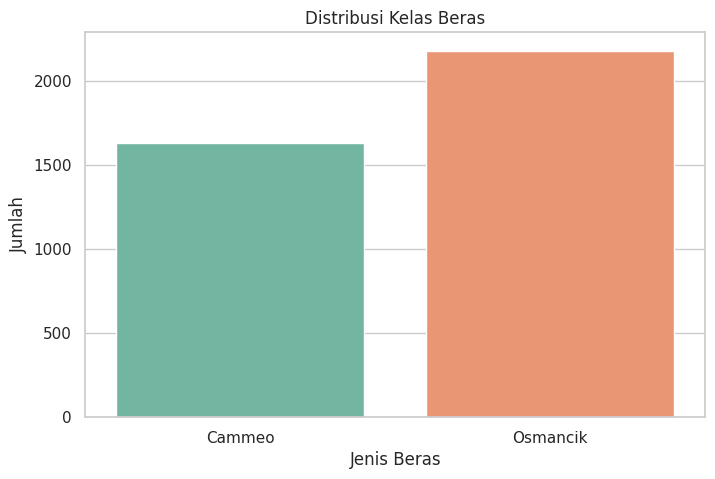

In [20]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x='Class',
    hue='Class',
    palette='Set2',
    legend=False
)

plt.title('Distribusi Kelas Beras')
plt.xlabel('Jenis Beras')
plt.ylabel('Jumlah')
plt.show()

In [21]:
garis_dasar = (
    df['Class'].value_counts(normalize=True).max()
)

print(
    "Garis dasar kelas mayoritas: {:.2f}%".format(
        garis_dasar * 100
    )
)

Garis dasar kelas mayoritas: 57.22%


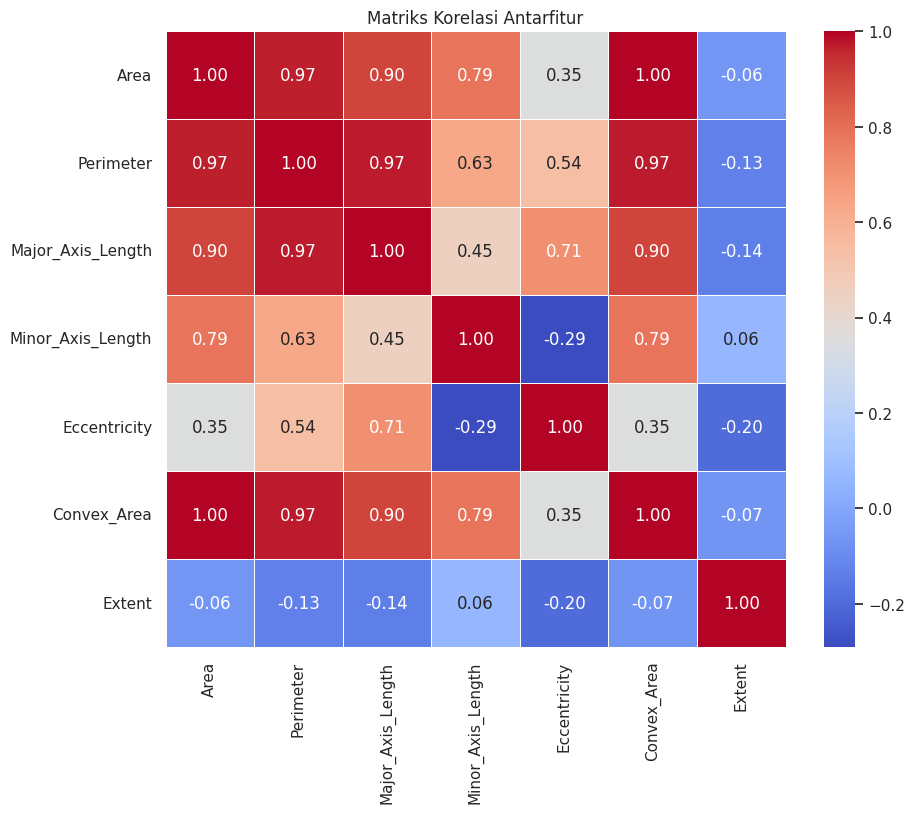

In [22]:
korelasi = df[numerik].corr()

plt.figure(figsize=(10, 8))

sns.heatmap(
    korelasi,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Matriks Korelasi Antarfitur')
plt.show()

In [23]:
pasangan_korelasi = []

for i in range(len(numerik)):
    for j in range(i + 1, len(numerik)):

        nilai = korelasi.iloc[i, j]

        if abs(nilai) > 0.8:
            pasangan_korelasi.append({
                'Fitur 1': numerik[i],
                'Fitur 2': numerik[j],
                'Korelasi': round(nilai, 4)
            })

tabel_korelasi = pd.DataFrame(pasangan_korelasi)

display(tabel_korelasi)

,Fitur 1,Fitur 2,Korelasi
0,Area,Perimeter,0.9665
1,Area,Major_Axis_Length,0.9030
2,Area,Convex_Area,0.9989
3,Perimeter,Major_Axis_Length,0.9719
4,Perimeter,Convex_Area,0.9699
5,Major_Axis_Length,Convex_Area,0.9034


In [24]:
target = 'Area'

kor_area = (
    df[numerik]
    .corr()[target]
    .drop(target)
    .abs()
    .sort_values(ascending=False)
)

print("Korelasi fitur terhadap Area:")
display(kor_area)

print("\nFitur yang perlu dicurigai:")

print(
    list(kor_area[kor_area > 0.95].index)
)

Korelasi fitur terhadap Area:


,Area
Convex_Area,0.998939
Perimeter,0.966453
Major_Axis_Length,0.903015
Minor_Axis_Length,0.787840
Eccentricity,0.352095
Extent,0.061184



Fitur yang perlu dicurigai:
['Convex_Area', 'Perimeter']


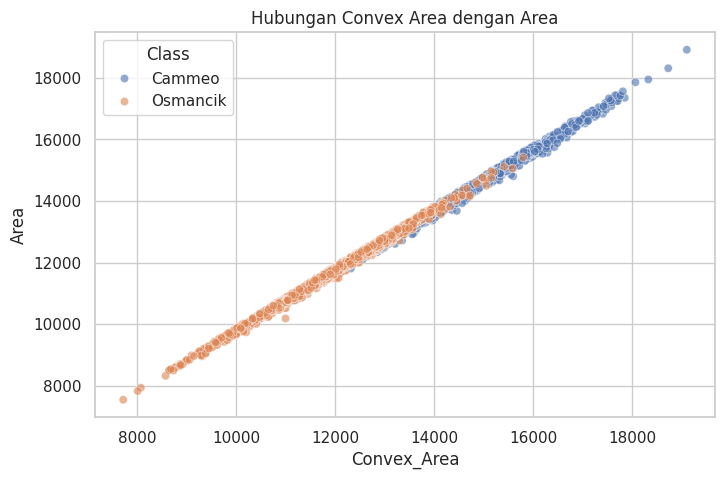

In [25]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x='Convex_Area',
    y='Area',
    hue='Class',
    alpha=0.6
)

plt.title('Hubungan Convex Area dengan Area')
plt.show()

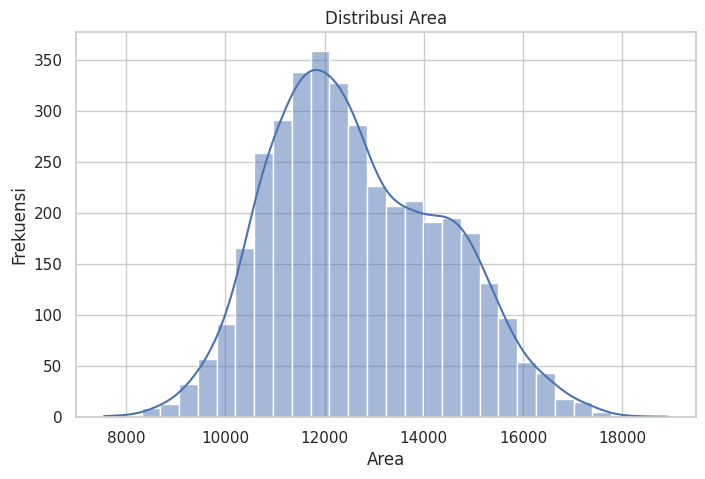

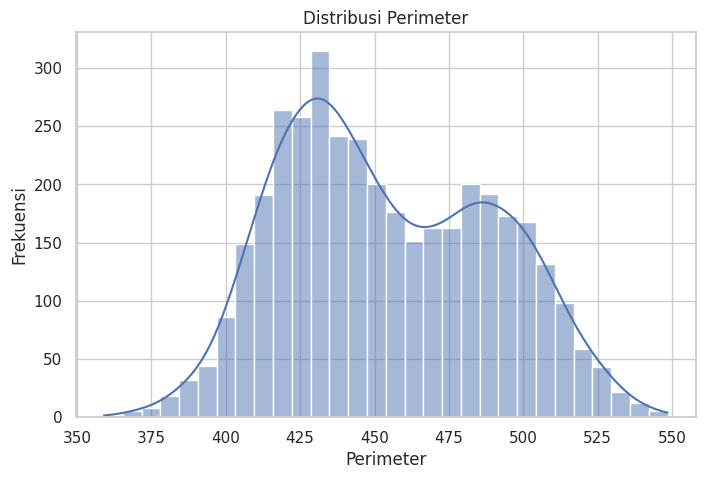

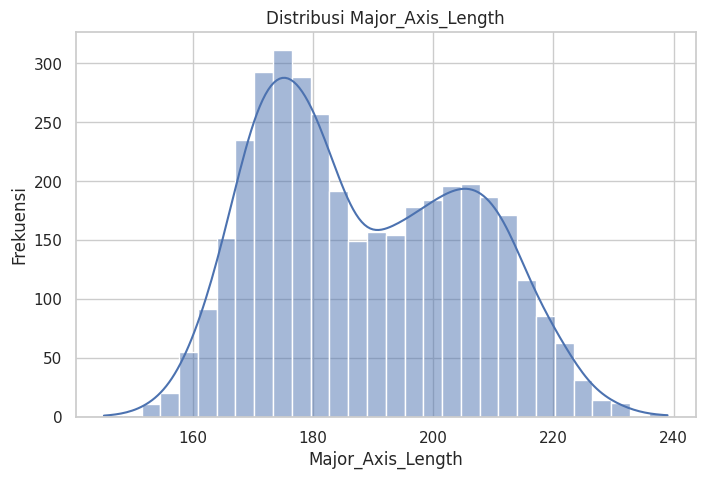

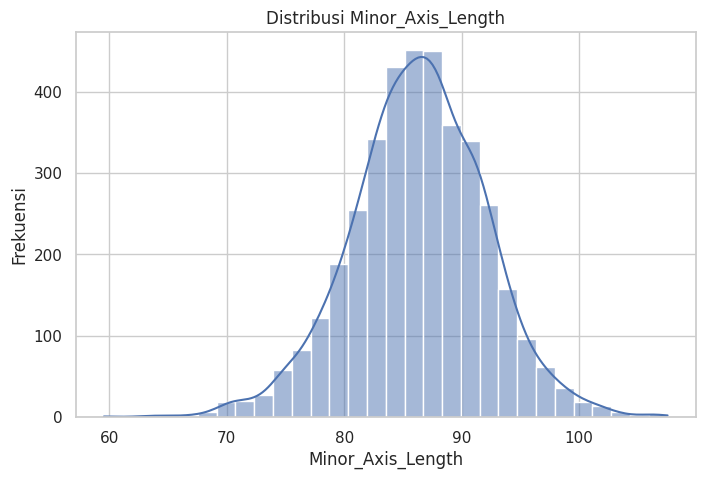

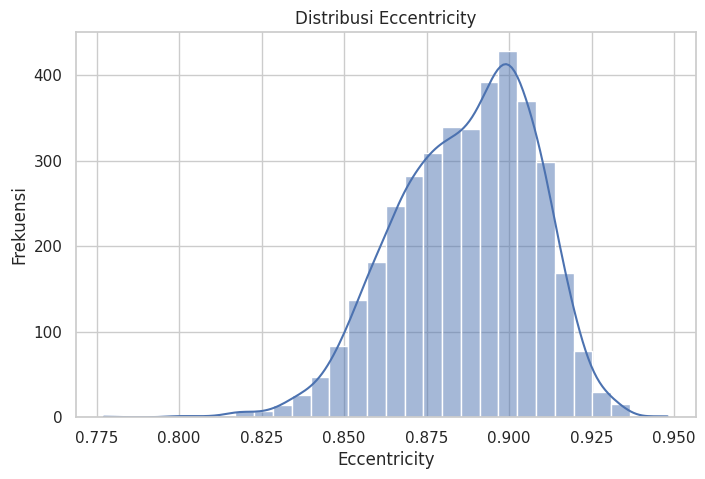

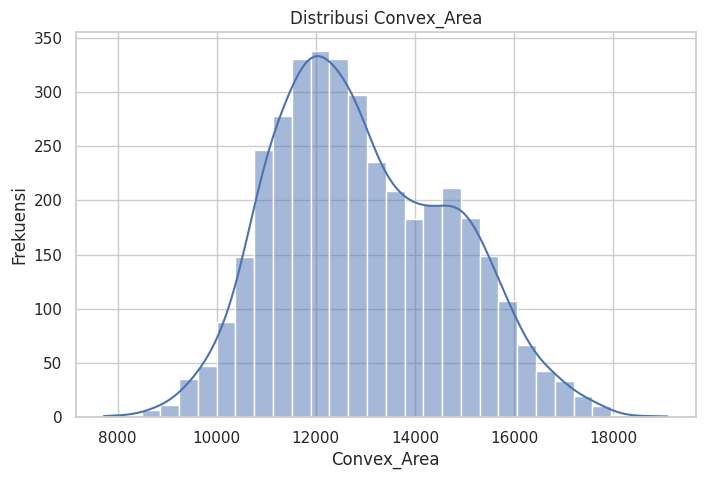

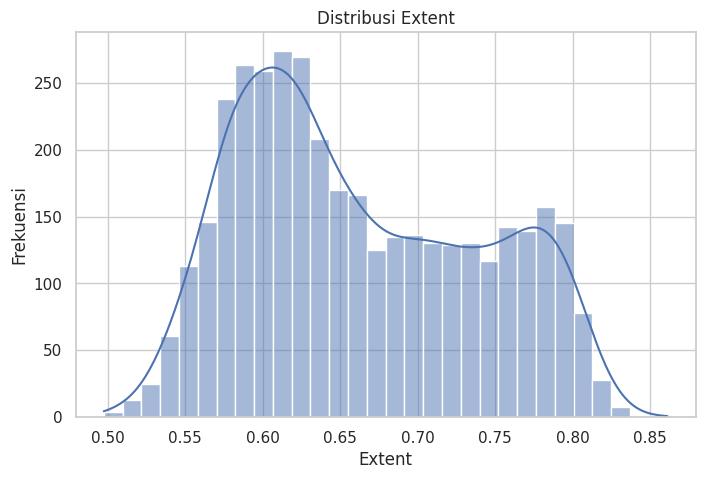

In [26]:
for kolom in numerik:

    plt.figure(figsize=(8, 5))

    sns.histplot(
        data=df,
        x=kolom,
        bins=30,
        kde=True
    )

    plt.title(f'Distribusi {kolom}')
    plt.xlabel(kolom)
    plt.ylabel('Frekuensi')
    plt.show()

,Area,Perimeter,Major_Axis_Length,Minor_Axis_Length,Eccentricity,Convex_Area,Extent
Class,,,,,,,
Cammeo,14162.892025,487.438942,205.478589,88.767532,0.901047,14494.426994,0.651420
Osmancik,11549.783486,429.415505,176.287755,84.479042,0.876271,11799.585780,0.669796


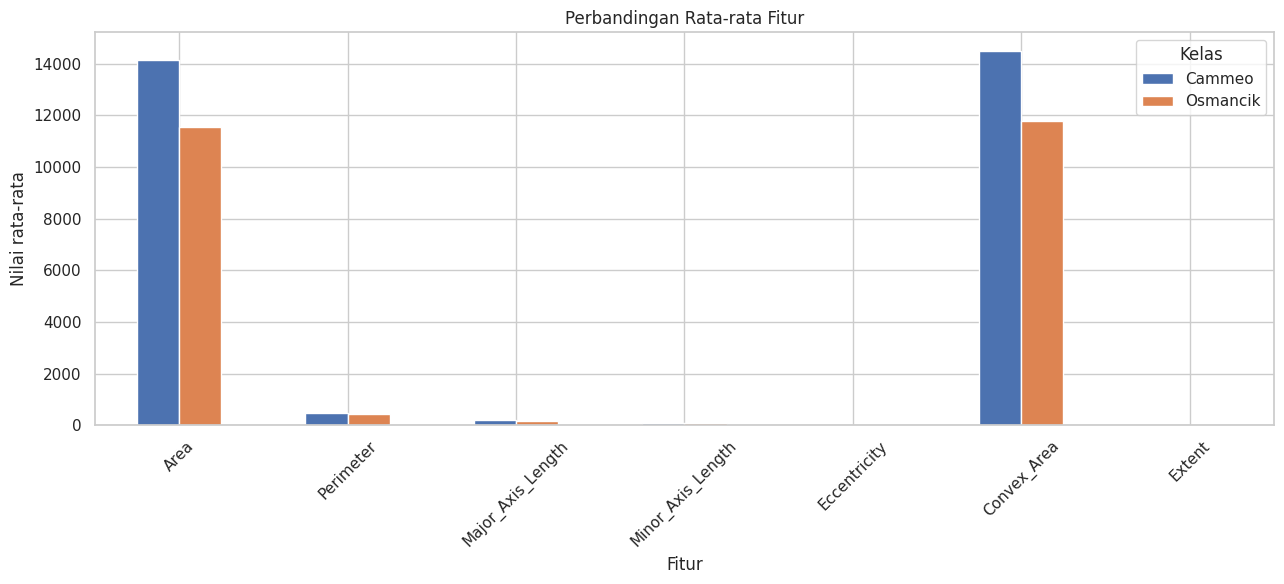

In [27]:
rata_rata_kelas = df.groupby('Class')[numerik].mean()

display(rata_rata_kelas)

rata_rata_kelas.T.plot(
    kind='bar',
    figsize=(13, 6)
)

plt.title('Perbandingan Rata-rata Fitur')
plt.xlabel('Fitur')
plt.ylabel('Nilai rata-rata')
plt.xticks(rotation=45)
plt.legend(title='Kelas')
plt.tight_layout()
plt.show()

In [28]:
keputusan = pd.DataFrame({
    'Pemeriksaan': [
        'Missing values',
        'Data duplikat',
        'Kolom konstan',
        'Kolom identifier',
        'Nilai mustahil',
        'Outlier'
    ],
    'Hasil': [
        df.isnull().sum().sum(),
        df.duplicated().sum(),
        list(kolom_konstan.index),
        list(kolom_identifier.index),
        'Perlu ditinjau dari hasil pemeriksaan',
        'Diperiksa menggunakan metode IQR'
    ],
    'Keputusan': [
        'Tangani jika ditemukan',
        'Periksa sebelum menghapus',
        'Hapus jika memang tidak informatif',
        'Tidak digunakan sebagai fitur',
        'Periksa validitas nilai',
        'Tidak otomatis dihapus'
    ]
})

display(keputusan)

,Pemeriksaan,Hasil,Keputusan
0,Missing values,0,Tangani jika ditemukan
1,Data duplikat,0,Periksa sebelum menghapus
2,Kolom konstan,[],Hapus jika memang tidak informatif
3,Kolom identifier,"[Perimeter, Major_Axis_Length, Minor_Axis_Leng...",Tidak digunakan sebagai fitur
4,Nilai mustahil,Perlu ditinjau dari hasil pemeriksaan,Periksa validitas nilai
5,Outlier,Diperiksa menggunakan metode IQR,Tidak otomatis dihapus


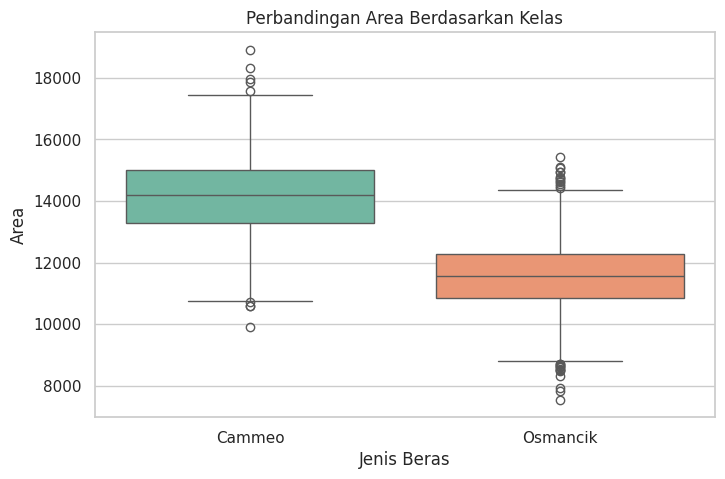

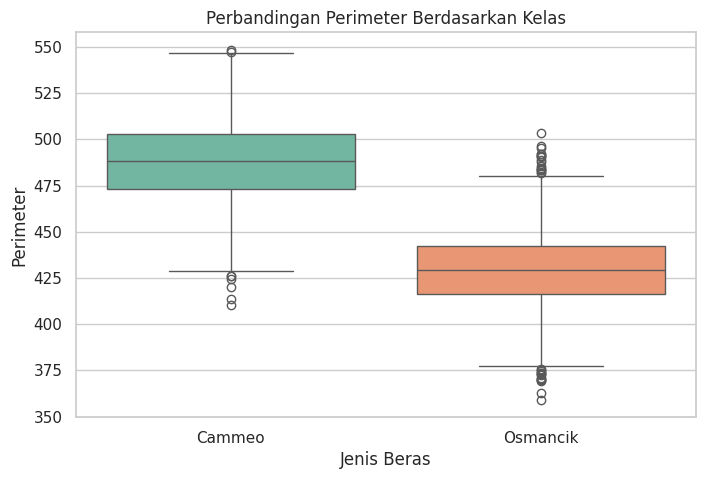

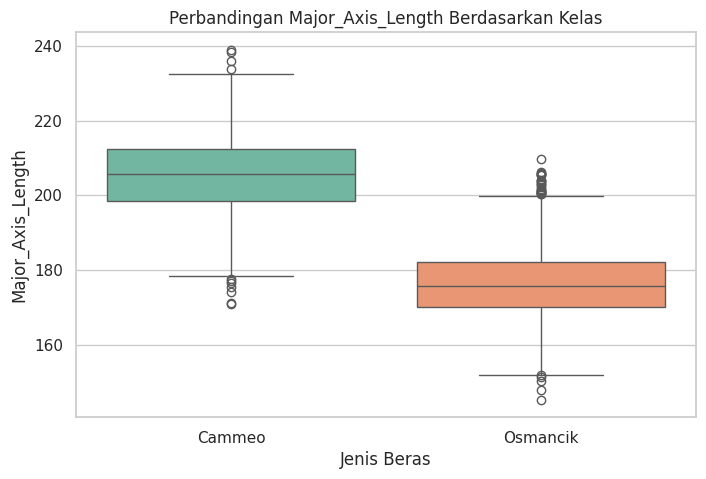

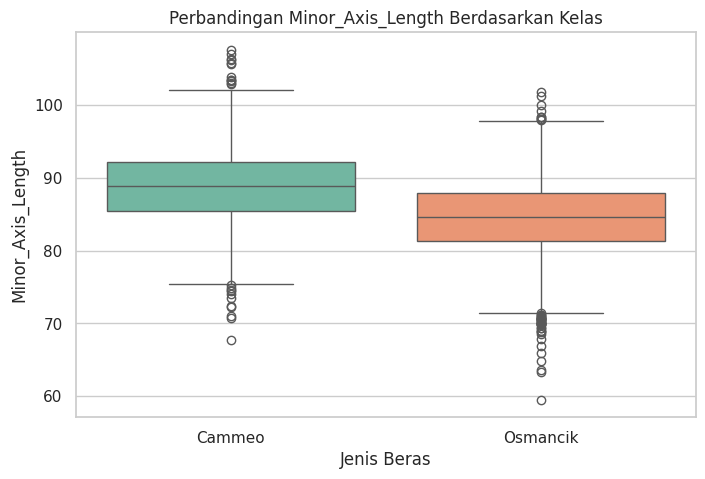

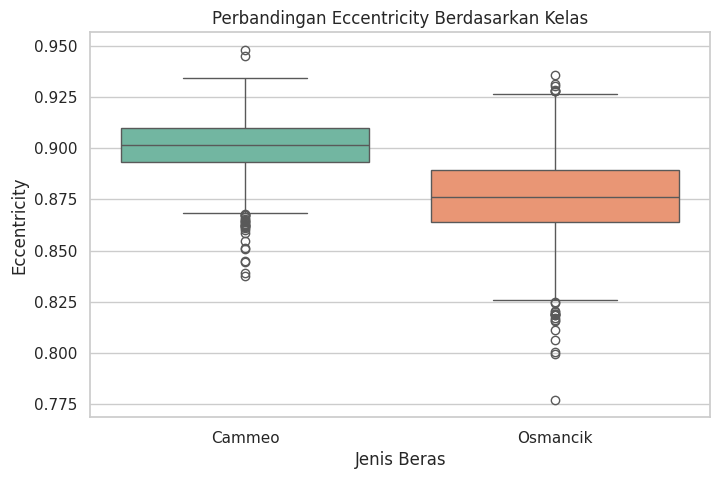

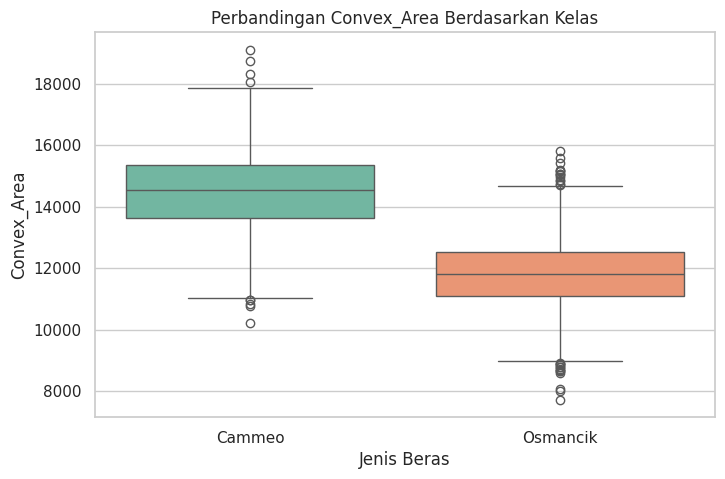

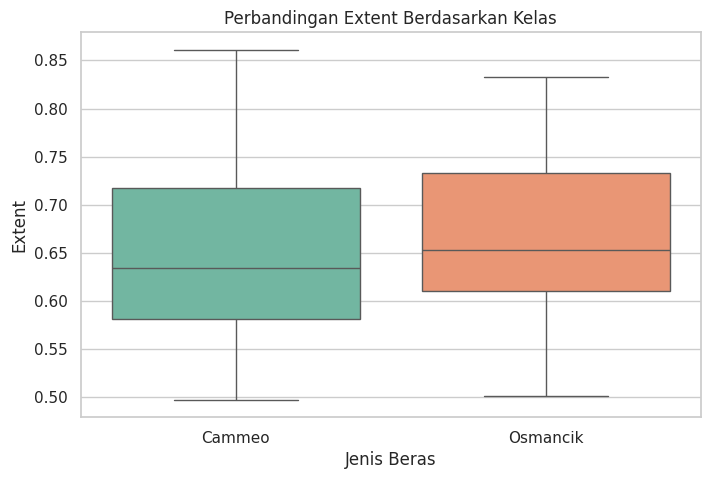

In [30]:
for kolom in numerik:

    plt.figure(figsize=(8, 5))

    sns.boxplot(
        data=df,
        x='Class',
        y=kolom,
        hue='Class',
        palette='Set2',
        legend=False
    )

    plt.title(f'Perbandingan {kolom} Berdasarkan Kelas')
    plt.xlabel('Jenis Beras')
    plt.ylabel(kolom)
    plt.show()